# Project Progress: прогнозування попиту для оптимізації складу

**Дані:** Online Retail II (UCI) — транзакції британського онлайн-гуртовика подарункових товарів, 01.12.2009 – 09.12.2011

**Бізнес-задача.** Склад має вирішувати, скільки одиниць кожного товару (SKU) замовити в постачальника на наступний місяць. Замовимо мало — втратимо продажі, багато — товар займає місце і заморожує гроші. Тому спочатку прогнозуємо попит, а потім на основі прогнозу і його похибки розв'язуємо оптимізаційну задачу поповнення.

### Архітектура

| Шар | Що це | Файли | Код |
|---|---|---|---|
| **Raw** | Excel з UCI | `data/raw/online_retail_II.xlsx` | — |
| **Bronze** | сирі дані як є: два аркуші + мітка аркуша | `data/bronze/transactions.parquet` | `src/pipeline.py` |
| **Silver** | очищені транзакції, тільки реальні продажі товарів + журнал очищення | `data/silver/` | `src/pipeline.py` |
| **Gold** | вітрини: тижневий ряд з ознаками, тиждень × товар, довідник товарів, ціни по тижнях | `data/gold/` | `src/pipeline.py`, `src/features.py` |
| **ML** | валідація, моделі, оптимізація — читають **тільки gold** | — | `src/validation.py`, `src/models.py`, `src/optimization.py` |

Шари будує `python -m src.pipeline`; після кожного шару — перевірки якості (`src/checks.py`), які зупиняють пайплайн, якщо дані «зламались». Цей ноутбук лише читає готові шари і показує результати.

### Зміст
1. **EDA & Preprocessing**: Bronze → Silver → Gold, аномалії, агрегація, характеристики ряду
2. **Схема валідації**: rolling-origin backtesting, горизонт, захист від data leakage
3. **Baselines**: наївні бенчмарки, перші робочі моделі, метрики
4. **Місток до оптимізації**: постановка задачі, перший прототип, обмеження
5. **Висновки та наступні кроки**

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import display
from statsmodels.tsa.stattools import adfuller

from src import config as cfg, models, optimization as opt, pipeline, plots
from src.checks import check, validate_bronze, validate_gold, validate_silver
from src.features import FEATURES
from src.validation import backtest, backtest_panel, features_leak_free, make_origins, week_span

H = cfg.H                      # горизонт прогнозу, 4 тижні (обґрунтування в розділі 2)
plots.setup_style()

if not pipeline.gold_exists():  # перший запуск: будуємо всі шари
    pipeline.run()

---
## 1. EDA & Preprocessing: Bronze → Silver → Gold

### 1.1 Bronze — сирі дані

Обидва аркуші Excel **без жодних змін** + колонка `source_sheet`, щоб знайти перекриття аркушів. `Customer ID` — персональні дані: для прогнозу по товарах він не потрібен, використовується лише в одному кроці очищення (пошук пар «замовлення–скасування»), значення ніде не показуємо.

In [2]:
bronze = pipeline.build_bronze()     # з кешу parquet; Excel читається лише при --rebuild
validate_bronze(bronze)
print(f"\nРядків: {len(bronze):,} | період: {bronze['InvoiceDate'].min()} — {bronze['InvoiceDate'].max()}")

display(bronze.drop(columns=["Customer ID"]).head(3))
display(pipeline.bronze_profile(bronze))
display(pipeline.bronze_issues(bronze))

✓ схема bronze: 8 колонок джерела + source_sheet
✓ InvoiceDate має тип дата
✓ Quantity — ціле число
✓ Invoice і StockCode без пропусків

Рядків: 1,067,371 | період: 2009-12-01 07:45:00 — 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,United Kingdom,Year 2009-2010


,тип,пропусків,% пропусків,унікальних
Invoice,str,0,0.00,53628
StockCode,str,0,0.00,5305
Description,str,4382,0.41,5698
Quantity,int64,0,0.00,1057
InvoiceDate,datetime64[us],0,0.00,47635
Price,float64,0,0.00,2807
Customer ID,float64,243007,22.77,5942
Country,str,0,0.00,43
source_sheet,str,0,0.00,2


,рядків,% від усіх
дублікати рядків (без source_sheet),34335,3.22
скасування (Invoice на C),19494,1.83
Quantity <= 0,22950,2.15
Price <= 0,6207,0.58
"службові коди (POST, DOT, M, AMAZONFEE...)",6093,0.57
StockCode з малими літерами (85123a vs 85123A),3471,0.33
пропущений Description,4382,0.41
пропущений Customer ID,243007,22.77
Country = Unspecified,756,0.07


In [3]:
# звідки дублікати? аркуші перекриваються: 1-9 грудня 2010 є в обох
overlap = bronze[(bronze["InvoiceDate"] >= "2010-12-01") & (bronze["InvoiceDate"] < "2010-12-10")]
print(overlap.groupby("source_sheet").size().to_string())
print("Дублікатів у цьому періоді:", overlap.duplicated(subset=pipeline.ORIGINAL_COLUMNS).sum())

stock_code = bronze["StockCode"]
print(f"Унікальних StockCode: {stock_code.nunique():,} -> після .upper(): {stock_code.str.strip().str.upper().nunique():,}")

# аномалія: найбільші рядки за модулем кількості
bronze.sort_values("Quantity", key=abs, ascending=False).head(4)[
    ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price"]]

source_sheet
Year 2009-2010    22523
Year 2010-2011    22523
Дублікатів у цьому періоді: 22844
Унікальних StockCode: 5,305 -> після .upper(): 5,131


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.04


**Аномалія: великі замовлення, які одразу скасували.** Два найбільші рядки (80 995 і 74 215 шт.) — помилкові замовлення, скасовані через 12–16 хвилин. Якщо просто викинути скасування (рядки з `C`), позитивне замовлення залишиться і створить фальшивий пік попиту. Тому в silver шукаємо пари «замовлення ↔ скасування» (той самий клієнт, товар і кількість, замовлення раніше за скасування) і видаляємо обидва рядки. Беремо великі скасування (≥ 1000 шт.), бо саме вони спотворюють ряд.

### 1.2 Silver — очищені транзакції

Кожен крок очищення записано в журнал: видно, скільки рядків прибрав кожен з них. Рядки без `Customer ID` **залишаємо**: це реальні продажі (ймовірно, покупці без акаунта), а прогнозуємо ми попит по товарах, не по клієнтах.

In [4]:
fake_orders, n_big_cancels = pipeline.find_fake_orders(pipeline.normalize_text(bronze))
print("Великих скасувань:", n_big_cancels)
print(f"Знайдено відповідних замовлень: {len(fake_orders)} | одиниць: {bronze.loc[fake_orders, 'Quantity'].sum():,}\n")

silver = pipeline.load_silver()
display(pipeline.load_cleaning_log())
validate_silver(silver)
print(f"\nSilver: {len(silver):,} рядків, {silver['StockCode'].nunique():,} товарів")

Великих скасувань: 43
Знайдено відповідних замовлень: 40 | одиниць: 263,001



,крок,видалено рядків,% від bronze
0,помилкові мега-замовлення,40,0.00
1,дублікати (перекриття аркушів),34335,3.22
2,скасування (Invoice на C),19104,1.79
3,службові коди,4790,0.45
4,Quantity <= 0 (складські коригування),3362,0.31
5,Price <= 0 (безкоштовні позиції),2566,0.24
6,РАЗОМ залишилось у silver,1003174,93.99


✓ усі Quantity > 0
✓ усі Price > 0
✓ немає скасувань
✓ тільки товарні коди
✓ StockCode у верхньому регістрі


✓ немає дублікатів
✓ персональних даних немає

Silver: 1,003,174 рядків, 4,706 товарів


### 1.3 EDA на silver

#### Агрегація: день чи тиждень?

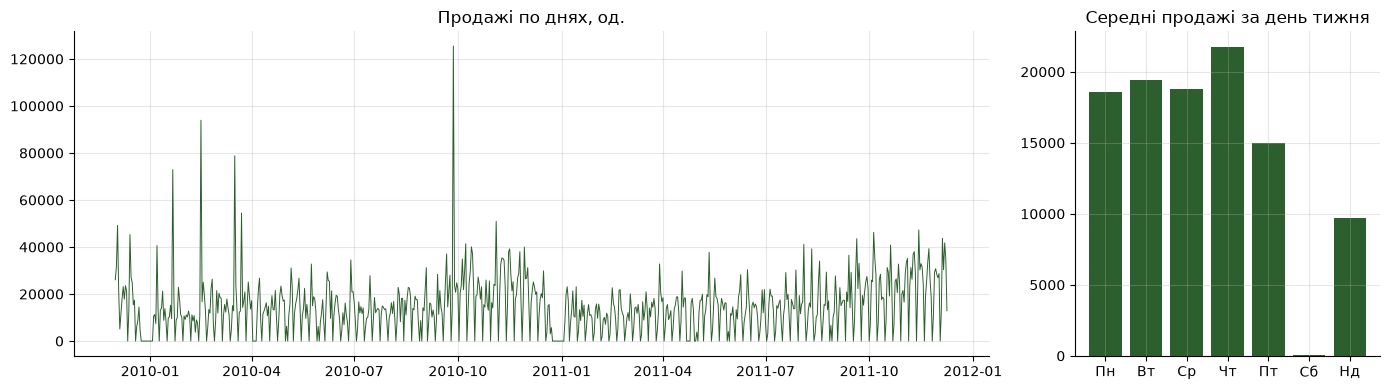

Днів з нульовими продажами: 135 з 739
Коефіцієнт варіації по днях: 0.81


In [5]:
daily = silver.set_index("InvoiceDate")["Quantity"].resample("D").sum()
plots.daily_sales(daily)

print("Днів з нульовими продажами:", (daily == 0).sum(), "з", len(daily))
print("Коефіцієнт варіації по днях:", round(daily.std() / daily.mean(), 2))

Денний ряд незручний: у суботу склад не працює (структурні нулі), є нулі на Різдво/Новий рік і банківські вихідні, великий шум. Рішення про закупівлю приймаються щотижня або раз на місяць, тому в gold **агрегуємо до тижнів** (Пн–Нд; мітка тижня — неділя).

#### Виручка, ціни та країни

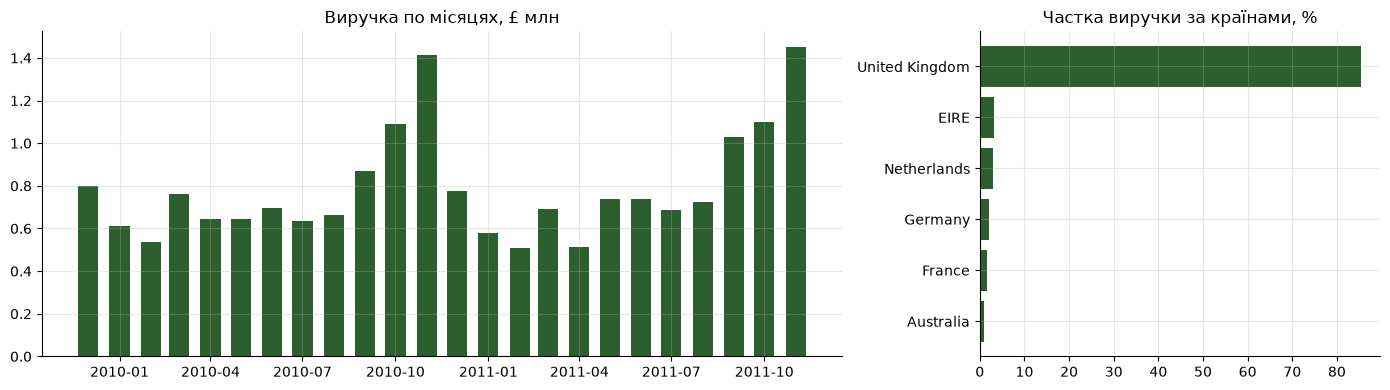

Загальна виручка: £19.3 млн
Частка Великої Британії: 85.4%
Ціна за одиницю: медіана £2.10, 95-й перцентиль £9.95
Кількість в рядку: медіана 4, 99-й перцентиль 108


In [6]:
monthly_revenue = silver.set_index("InvoiceDate")["Revenue"].resample("MS").sum()[:-1]   # грудень 2011 неповний
country_revenue = silver.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
country_share = country_revenue / country_revenue.sum() * 100
plots.revenue_and_countries(monthly_revenue, country_share)

print(f"Загальна виручка: £{silver['Revenue'].sum() / 1e6:.1f} млн")
print(f"Частка Великої Британії: {country_share['United Kingdom']:.1f}%")
print(f"Ціна за одиницю: медіана £{silver['Price'].median():.2f}, 95-й перцентиль £{silver['Price'].quantile(0.95):.2f}")
print(f"Кількість в рядку: медіана {silver['Quantity'].median():.0f}, 99-й перцентиль {silver['Quantity'].quantile(0.99):.0f}")

- Виручка має ту саму сезонність, що й кількість: пік у вересні–листопаді.
- ~85% виручки — Велика Британія, тому один склад і один ряд по всіх країнах — розумне спрощення.
- Товари дешеві (медіана ~£2), продаються гуртовими пачками (по 12, 24...), але бувають рядки на тисячі одиниць — разові гуртові замовлення. Їх розбираємо на рівні тижнів у gold.

---
### 1.4 Gold — вітрини для моделей

1. **`weekly_total`** — загальний тижневий ряд: кількість, виручка, інвойси, активні товари, прапорці аномалій, очищена ціль і ознаки.
2. **`weekly_sku`** — матриця тиждень × товар (тижні без продажів = 0).
3. **`dim_product`** — довідник товарів: опис, медіанна ціна, обсяг, ABC-клас.
4. **`sku_weekly_prices`** — ціни по тижнях, щоб оптимізація брала ціну «станом на дату» без звернення до silver.

Перший і останній тижні неповні (дані починаються у вівторок і закінчуються в п'ятницю) — відкинуто.

**Аномалії на тижневому рівні.** Робастний z-score: відхилення від ковзної медіани (9 тижнів), поділене на MAD, поріг |z| > 3.5.
- z < −3.5 — тижні Різдва/Нового року (склад закритий). Це календарна подія, а не помилка — **не чіпаємо**, лише прапорець.
- z > +3.5 — разові гуртові замовлення. Для навчання моделей обрізаємо їх до `медіана + 3.5·MAD` (`quantity_clean`). Метрики рахуємо на сирій `quantity`.

**Ознаки** мають лаг ≥ H = 4 тижні або є календарем, тож на момент прогнозу вони вже відомі: `level_lag4` — середнє за тижні t−7 … t−4; `sin1, cos1, sin2, cos2` — Фур'є-члени від номера тижня (плавна річна сезонність).

In [7]:
gold = pipeline.load_gold()
gold_weekly, gold_sku, dim_product = gold["weekly"], gold["sku"], gold["product"]
validate_gold(gold_weekly, gold_sku, dim_product)

print(f"\nТижнів: {len(gold_weekly)} | {week_span(gold_weekly.index[0])} … {week_span(gold_weekly.index[-1])}")
print("Коефіцієнт варіації по тижнях:", round(gold_weekly["quantity"].std() / gold_weekly["quantity"].mean(), 2))
gold_weekly.loc[gold_weekly["is_spike"] | gold_weekly["is_closed_week"],
                ["quantity", "quantity_clean", "is_spike", "is_closed_week"]]

✓ тижні йдуть підряд, без пропусків
✓ немає пропусків у цільовій змінній
✓ gold_weekly і gold_sku мають однакові тижні
✓ сума по товарах = загальна сума (gold узгоджений)
✓ кожен товар з gold_sku є в довіднику
✓ обрізання піків не зачіпає 2011 рік (тестовий період)
✓ ознаки заповнені (крім перших тижнів, де ще немає лагу)

Тижнів: 104 | 07.12.2009–13.12.2009 … 28.11.2011–04.12.2011
Коефіцієнт варіації по тижнях: 0.39


,quantity,quantity_clean,is_spike,is_closed_week
week,,,,
2009-12-27,"27,786.00","27,786.00",False,True
2010-01-03,0.00,0.00,False,True
2010-01-24,"135,351.00","133,972.06",True,False
2010-02-21,"173,603.00","147,715.06",True,False
2010-03-21,"155,858.00","147,715.06",True,False
2010-10-03,"237,160.00","185,110.06",True,False
2011-01-02,0.00,0.00,False,True


### 1.5 EDA на gold: характеристики часового ряду

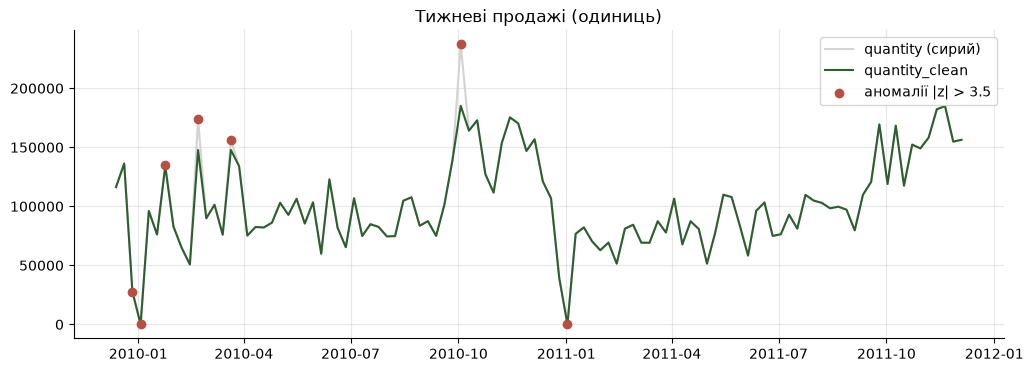

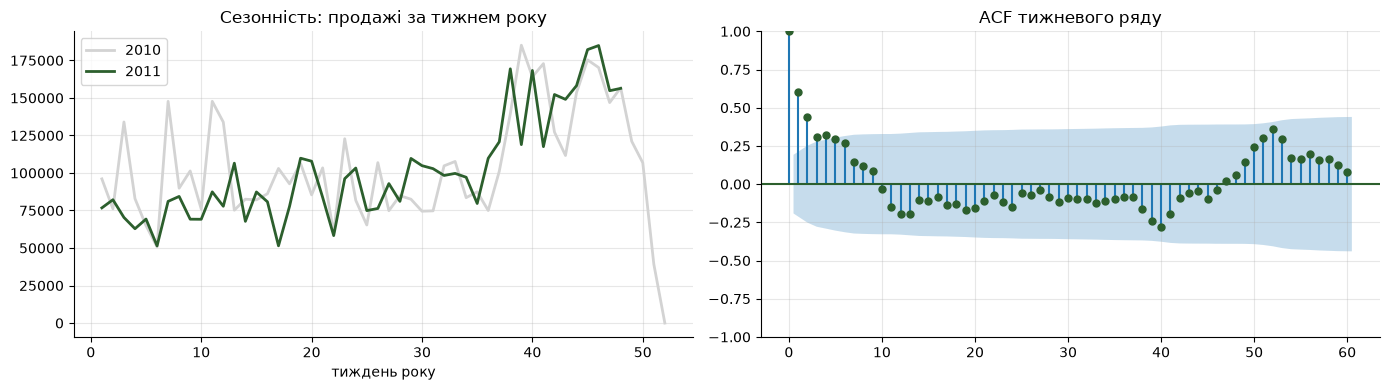

ADF p-value: 0.004


In [8]:
plots.weekly_anomalies(gold_weekly)
plots.seasonality_and_acf(gold_weekly["quantity_clean"])
print("ADF p-value:", round(adfuller(gold_weekly["quantity_clean"], result_object=False)[1], 3))

**Характеристики ряду:**
- **Річна сезонність сильна**: з вересня продажі ростуть, пік у листопаді (магазини закуповуються до Різдва), потім провал до нуля на Новий рік. ACF: значущі перші лаги і хвиля біля лагу 52.
- **Тренд** слабкий: 2011 трохи вище за 2010 у другому півріччі. ADF відкидає одиничний корінь — сильного стохастичного тренду немає.
- **Тижневої сезонності** після агрегації немає — суботні нулі «розчинились».
- **Лише 2 сезонні цикли** (104 тижні) — для Holt-Winters чи SARIMA з періодом 52 замало, тому сезонність задаємо ознаками (Фур'є, лаг).

#### Рівень товарів: концентрація та переривчастість

,товарів,частка_обсягу,медіана_тижнів_без_продажів
abc_class,,,
A,1072,80.00,23.08
B,1143,15.00,48.08
C,2491,5.00,84.62


80% обсягу дають 1072 товарів (23% асортименту)
Медіанний товар не продається 68% тижнів


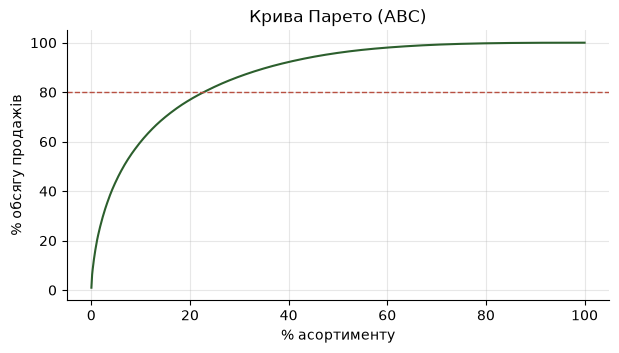

In [9]:
abc_summary = dim_product.groupby("abc_class").agg(
    товарів=("total_quantity", "size"),
    частка_обсягу=("total_quantity", lambda s: s.sum() / dim_product["total_quantity"].sum() * 100),
    медіана_тижнів_без_продажів=("zero_weeks_share", lambda s: s.median() * 100),
)
display(abc_summary)

n_a = (dim_product["abc_class"] == "A").sum()
print(f"80% обсягу дають {n_a} товарів ({n_a / len(dim_product) * 100:.0f}% асортименту)")
print(f"Медіанний товар не продається {dim_product['zero_weeks_share'].median() * 100:.0f}% тижнів")
plots.pareto(dim_product["total_quantity"])

Класичний ABC-розподіл: ~23% товарів дають 80% обсягу. Товари класу C продаються рідко (переривчастий попит) — для них потрібні окремі методи (Croston/TSB), це наступний етап. Для прототипу беремо **топ-30 товарів класу A**.

---
## 2. Схема валідації (Data Leakage & Split)

**Горизонт H = 4 тижні** — приблизно місячний цикл закупівлі: замовлення постачальнику робиться на місяць вперед.

**Rolling-origin backtesting (expanding window).** Випадковий train/test split не підходить — модель «підглядала» б у майбутнє. Замість цього:
- беремо точку відліку (origin), вчимося на всьому, що було **до** неї, прогнозуємо 4 тижні вперед;
- зсуваємо origin на 2 тижні і повторюємо;
- 13 фолдів покривають кінець травня – грудень 2011, включно з передріздвяним піком — найважливішим періодом для складу.

**Захист від data leakage:**
1. Модель бачить лише `train = series[:origin]`.
2. Ознаки мають лаг ≥ H, тому для кожного тестового тижня вони рахуються тільки з train (перевіряємо нижче).
3. Нормалізація ознак — тільки на train кожного фолду.
4. Топ-товари вибираємо за продажами **до** першого тестового тижня; ціни для оптимізації — лише до дати планування.
5. Обрізання піків зачіпає лише 2010 рік (перевірено в gold), метрики рахуємо на сирій `quantity`.

**Межа шарів:** з цього місця все читається тільки з gold (`gold_weekly`, `gold_sku`, `dim_product`, `gold["prices"]`) — bronze і silver далі не використовуються.

Фолдів: 13
Перший тестовий тиждень: 23.05.2011–29.05.2011
Останній тестовий тиждень: 28.11.2011–04.12.2011
✓ у всіх 13 фолдах ознаки тестових тижнів рахуються лише з train (немає leakage)


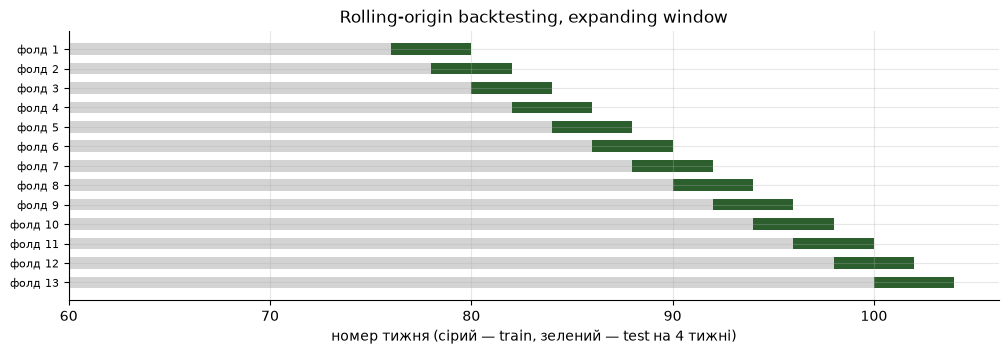

In [10]:
origins = make_origins(len(gold_weekly))
print("Фолдів:", len(origins))
print("Перший тестовий тиждень:", week_span(gold_weekly.index[origins[0]]))
print("Останній тестовий тиждень:", week_span(gold_weekly.index[origins[-1] + H - 1]))

check(features_leak_free(gold_weekly["quantity_clean"], gold_weekly[FEATURES], origins),
      f"у всіх {len(origins)} фолдах ознаки тестових тижнів рахуються лише з train (немає leakage)")
plots.backtest_folds(origins, H)

---
## 3. Базові моделі (Baselines)

### 3.1 Метрики
- **MAE** — середня абсолютна помилка в одиницях товару (зрозуміло бізнесу).
- **RMSE** — сильніше штрафує великі промахи (великий промах = дефіцит або переповнення складу).
- **WAPE** = Σ|помилка| / Σ факт — відсоткова помилка, яка не «вибухає» на тижнях з нульовими продажами (на відміну від MAPE).
- **MASE** — помилка відносно наївного прогнозу на train; < 1 — краще за наївний.
- **Bias, %** — систематичне зміщення: > 0 означає, що модель **занижує** прогноз (ризик дефіциту).

### 3.2 Наївні бенчмарки
- **Naive**: наступні 4 тижні = останній відомий тиждень.
- **Seasonal Naive**: = ті самі тижні рік тому (лаг 52).
- **Moving Average (4)**: = середнє за останні 4 тижні.

### 3.3 Перші робочі моделі
- **ETS (Holt, затухаючий тренд)** — експоненційне згладжування рівня і тренду. Сезонну компоненту не беремо: даних лише на 2 сезони.
- **Ridge + Fourier** — регресія на ознаках з gold (`level_lag4` + Фур'є-сезонність). Регуляризація потрібна, бо рядків для навчання мало.

Код моделей — `src/models.py`, backtest і метрики — `src/validation.py`.

In [11]:
total_models = {
    "Naive": models.naive,
    "Seasonal Naive": models.seasonal_naive,
    "Moving Average (4)": models.moving_average,
    "ETS (Holt, damped)": models.ets_holt,
    "Ridge + Fourier": models.ridge_fourier(gold_weekly[FEATURES]),
}

results, predictions = {}, {}
for name, fn in total_models.items():
    results[name], predictions[name] = backtest(fn, gold_weekly["quantity_clean"], gold_weekly["quantity"], origins)

pd.DataFrame(results).T.sort_values("WAPE, %")

,MAE,RMSE,"WAPE, %",MASE,"Bias, %"
"ETS (Holt, damped)","18,278.64","25,017.90",15.46,0.71,8.64
Ridge + Fourier,"18,965.99","23,302.67",16.04,0.73,6.71
Moving Average (4),"19,180.10","26,034.43",16.22,0.74,10.51
Seasonal Naive,"20,959.37","26,184.89",17.72,0.81,3.71
Naive,"21,777.12","27,716.55",18.41,0.84,3.41


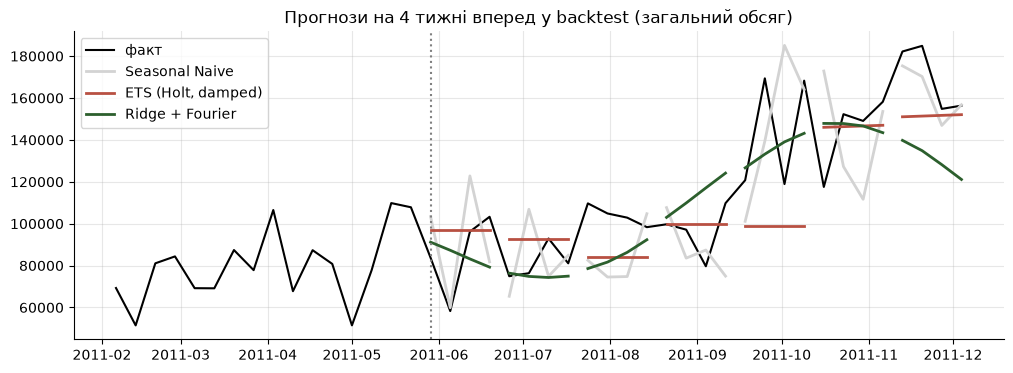

In [12]:
plots.backtest_forecasts(gold_weekly["quantity"], predictions, origins, H)

**Висновки по загальному ряду:**
- Наївні методи дають WAPE 16–18%. Naive і Seasonal Naive найменш зміщені, але шумні: Seasonal Naive переносить минулорічні разові піки в цей рік.
- ETS (Holt, damped) має найменші MAE/WAPE, Ridge + Fourier — найменший RMSE (менше великих промахів) і менший bias, бо «знає» про осіннє зростання. Обидві мають MASE ≈ 0.7, тобто на ~30% кращі за наївний прогноз.
- Різниця між моделями невелика — ряд короткий (2 сезони) і шумний.
- Усі моделі мають **позитивний bias** — недооцінюють осіннє зростання. Для складу це ризик дефіциту саме в найприбутковіший період: аргумент і для складніших моделей, і для страхового запасу в оптимізації.

### 3.4 Baselines на рівні товарів (топ-30, клас A)

In [13]:
top_skus = (gold_sku.iloc[:origins[0]].sum()                 # лише дані до першого тестового тижня
                    .sort_values(ascending=False).head(cfg.TOP_N_SKUS).index)
sku_panel = gold_sku[top_skus]

print(f"Частка топ-30 у загальному обсязі: {sku_panel.values.sum() / gold_weekly['quantity'].sum() * 100:.1f}%")
print(f"Медіанний коефіцієнт варіації: {(sku_panel.std() / sku_panel.mean()).median():.2f}")
display(dim_product.loc[top_skus[:5], ["description", "median_price", "abc_class"]])

sku_models = {
    "Naive": models.naive,
    "Seasonal Naive": models.seasonal_naive,
    "Moving Average (4)": models.moving_average,
    "Moving Average (8)": lambda train: models.moving_average(train, window=8),
}
sku_results, sku_predictions = {}, {}
for name, fn in sku_models.items():
    sku_results[name], sku_predictions[name] = backtest_panel(fn, sku_panel, origins)

pd.DataFrame(sku_results).T.sort_values("WAPE, %")

Частка топ-30 у загальному обсязі: 13.8%
Медіанний коефіцієнт варіації: 0.84


,description,median_price,abc_class
StockCode,,,
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,0.29,A
21212,PACK OF 72 RETROSPOT CAKE CASES,0.55,A
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2.95,A
85099B,JUMBO BAG RED RETROSPOT,1.95,A
17003,BROCADE RING PURSE,0.29,A


,"WAPE, %","Bias, %"
Moving Average (8),61.40,1.83
Moving Average (4),63.05,2.56
Naive,73.64,5.12
Seasonal Naive,96.15,-38.35


На рівні товарів помилка набагато більша (WAPE ~60%): попит «рваний» — одне гуртове замовлення може бути більшим за місяць звичайних продажів. Найкраще працює **ковзне середнє за 8 тижнів** — воно згладжує разові піки. Seasonal Naive найгірший: минулорічні разові піки не повторюються.

Висновки для оптимізації:
1. Точкового прогнозу недостатньо — потрібен **розподіл помилки**, щоб обирати страховий запас.
2. Помилки з backtest можна використати як емпіричний розподіл для генерації сценаріїв попиту.

---
## 4. Місток до оптимізації

### 4.1 Постановка задачі поповнення складу
Для кожного товару *i* (топ-30) вирішуємо, скільки одиниць $q_i$ мати на складі на наступні 4 тижні.

**Параметри:**
- $D_{is}$ — попит товару *i* у сценарії *s*: прогноз MA(8) × (1 + випадкова помилка з backtest), $s = 1..S$
- $c_i$ — закупівельна ціна, $p_i$ — штраф за дефіцит (втрачена маржа), $h_i$ — витрати на залишок (зберігання, заморожені гроші, ризик, що сезонний товар не продасться)
- $V$ — місткість складу під ці товари

**Модель (стохастичне ЛП, sample average approximation):**

$$\min_{q,u,o} \; \frac{1}{S}\sum_{s}\sum_{i} \left(p_i\, u_{is} + h_i\, o_{is}\right)$$
$$u_{is} \ge D_{is} - q_i, \quad o_{is} \ge q_i - D_{is}, \quad \sum_i q_i \le V, \quad q_i, u_{is}, o_{is} \ge 0$$

$u_{is}$ — дефіцит, $o_{is}$ — залишок. Без обмеження місткості це окремий newsvendor для кожного товару (оптимум — квантиль попиту рівня $p/(p+h)$). Обмеження $V$ «зв'язує» товари: місце дістається тим, де дефіцит найдорожчий.

**Припущення (в даних цього немає, `src/config.py`):** закупівельна ціна = 60% ціни продажу, втрачена маржа = 40% ціни, місткість вимірюємо в одиницях товару.

**Як трактуємо $h$ — ключове припущення.** Базовий випадок: непроданий залишок **не пропадає**, а переходить у наступний місяць, тому $h$ — лише зберігання і заморожені гроші, 15% закупівельної ціни (≈ 9% ціни продажу). Тоді $p/(p+h) ≈ 0.82$: дефіцит набагато дорожчий, і оптимум — тримати запас вище прогнозу. Якщо ж товар сезонний і залишок пропадає, $h$ = вся закупівельна ціна, $p/(p+h) = 0.4$, і оптимум — замовляти **менше** медіани. Що ближче до реальності, ми не знаємо, тому в 4.4 перевіряємо весь діапазон.

### 4.2 Прототип на одному фолді

In [14]:
# тестуємо на останньому фолді: плануємо 4 тижні, а потім дивимось, що було насправді
last = len(origins) - 1
o = origins[last]
plan_weeks = gold_weekly.index[o:o + H]
print(f"Плануємо тижні: {week_span(plan_weeks[0])} … {week_span(plan_weeks[-1])}")

best = "Moving Average (8)"
forecast_4w = pd.Series({sku: sku_predictions[best][sku][last * H:(last + 1) * H].sum() for sku in top_skus})
actual_4w = sku_panel.iloc[o:o + H].sum()

# відносні помилки 4-тижневого прогнозу з фолдів, що повністю закінчились до планування (без leakage)
rel_errors = opt.relative_errors(sku_predictions[best], sku_panel, origins, plan_origin=o)
print("Помилок для сценаріїв:", len(rel_errors))
print("Максимальна відносна помилка:", round(rel_errors.max(), 2))
print("Квантилі відносної помилки (5%, 50%, 95%):", np.round(np.quantile(rel_errors, [0.05, 0.5, 0.95]), 2))

price = opt.price_asof(gold["prices"], top_skus, before_week=plan_weeks[0])   # ціни лише до дати планування
costs = opt.cost_params(price)
scenarios = opt.make_scenarios(forecast_4w, rel_errors)

Плануємо тижні: 07.11.2011–13.11.2011 … 28.11.2011–04.12.2011
Помилок для сценаріїв: 315
Максимальна відносна помилка: 3.18
Квантилі відносної помилки (5%, 50%, 95%): [-0.74 -0.06  1.08]


In [15]:
plan_free, cost_free, _ = opt.solve_replenishment(scenarios, costs["shortage"], costs["holding"])
capacity = round(cfg.CAPACITY_SHARE * plan_free.sum(), -3)
plan_cap, cost_cap, shadow_price = opt.solve_replenishment(scenarios, costs["shortage"], costs["holding"], capacity)

print(f"Прогноз на 4 тижні (сума): {forecast_4w.sum():,.0f} од.")
print(f"План без обмеження місця: {plan_free.sum():,.0f} од., очікувані витрати £{cost_free:,.0f}")
print(f"План з місткістю {capacity:,.0f}: {plan_cap.sum():,.0f} од., очікувані витрати £{cost_cap:,.0f}")
print(f"Тіньова ціна місткості: £{shadow_price:.3f} за 1 додаткову одиницю місця")
print(f"\nФактичний попит за ці 4 тижні: {actual_4w.sum():,.0f} од.")

plans = {"замовити = прогноз": forecast_4w, "ЛП без обмеження місця": plan_free, f"ЛП з місткістю {capacity:,.0f}": plan_cap}
compare = pd.DataFrame({
    "одиниць на складі": {k: p.sum() for k, p in plans.items()},
    "реальні витрати, £": {k: opt.realized_cost(p, actual_4w, costs["shortage"], costs["holding"]) for k, p in plans.items()},
})
compare["vs прогноз, %"] = (compare["реальні витрати, £"] / compare["реальні витрати, £"].iloc[0] - 1) * 100
compare

Прогноз на 4 тижні (сума): 53,622 од.
План без обмеження місця: 77,244 од., очікувані витрати £4,951
План з місткістю 66,000: 66,000 од., очікувані витрати £5,103
Тіньова ціна місткості: £0.030 за 1 додаткову одиницю місця

Фактичний попит за ці 4 тижні: 61,373 од.


,одиниць на складі,"реальні витрати, £","vs прогноз, %"
замовити = прогноз,"53,622.50","8,373.09",0.00
ЛП без обмеження місця,"77,244.36","4,664.70",-44.29
"ЛП з місткістю 66,000","66,000.00","5,018.09",-40.07


На останньому фолді ЛП, яке враховує асиметрію витрат і розподіл помилки, дає фактичні витрати на 44% нижчі, ніж «замовити рівно прогноз». Модель тримає страховий запас, бо помилки скошені вправо, а дефіцит дорожчий. Тіньова ціна показує, скільки коштує одна додаткова одиниця місця на складі — основа для prescriptive-рішень («чи варто орендувати додаткове місце в сезон»).

**Але це один фолд, і саме передріздвяний пік, де прогноз занижений на 14%.** Тут будь-яка політика «замовляй більше» виграє майже автоматично. Тому перевіряємо оптимізацію так само, як прогноз, — на всіх фолдах.

### 4.3 Перевірка на всіх фолдах

На кожному фолді повторюємо те саме: прогноз MA(8), сценарії з помилок **попередніх** фолдів, ціни до дати планування, ЛП → фактичні витрати. Фолди 1–3 пропускаємо: до них менше 50 помилок, сценаріям нема з чого будуватись. Залишається 10 фолдів, липень – грудень 2011.

Порівнюємо з двома простими політиками:
- **замовити = прогноз**;
- **запас під 95% сервісу** — 95-й перцентиль сценаріїв, типова складська евристика, яка не дивиться на витрати.

In [16]:
policy_costs = opt.backtest_policies(sku_predictions[best], sku_panel, origins, gold["prices"], gold_weekly.index)

by_fold = policy_costs[[opt.FORECAST, opt.SERVICE, opt.LP, opt.LP_CAP]].copy()
by_fold.insert(0, "факт vs прогноз, %", (policy_costs["факт, од."] / policy_costs["прогноз, од."] - 1) * 100)
by_fold.insert(0, "тижні", [f"{d:%d.%m}–{d + pd.Timedelta(days=4 * 7 - 1):%d.%m}" for d in policy_costs["початок"]])
display(by_fold.round(0))

opt.savings_summary(policy_costs)

,тижні,"факт vs прогноз, %",замовити = прогноз,запас під 95% сервісу,ЛП,ЛП з місткістю
фолд,,,,,,
4,04.07–31.07,-1.00,"2,758.00","5,653.00","3,083.00","2,763.00"
5,18.07–14.08,14.00,"5,868.00","6,062.00","5,155.00","5,368.00"
6,01.08–28.08,23.00,"8,934.00","6,085.00","6,443.00","7,223.00"
7,15.08–11.09,5.00,"3,557.00","7,197.00","3,147.00","3,093.00"
8,29.08–25.09,-7.00,"2,318.00","6,878.00","2,734.00","2,538.00"
9,12.09–09.10,6.00,"5,494.00","5,075.00","3,689.00","3,904.00"
10,26.09–23.10,-8.00,"4,137.00","5,726.00","2,295.00","2,640.00"
11,10.10–06.11,5.00,"5,222.00","6,208.00","3,887.00","4,391.00"
12,24.10–20.11,44.00,"10,852.00","6,131.00","7,810.00","8,272.00"


,"витрати за всі фолди, £","vs «замовити = прогноз», %","медіана по фолдах, %","фолдів, де краще за baseline"
замовити = прогноз,"57,512.22",0.00,0.00,0
запас під 95% сервісу,"60,994.29",6.05,11.09,4
ЛП,"42,907.44",-25.39,-26.73,8
ЛП з місткістю,"45,210.50",-21.39,-17.54,8


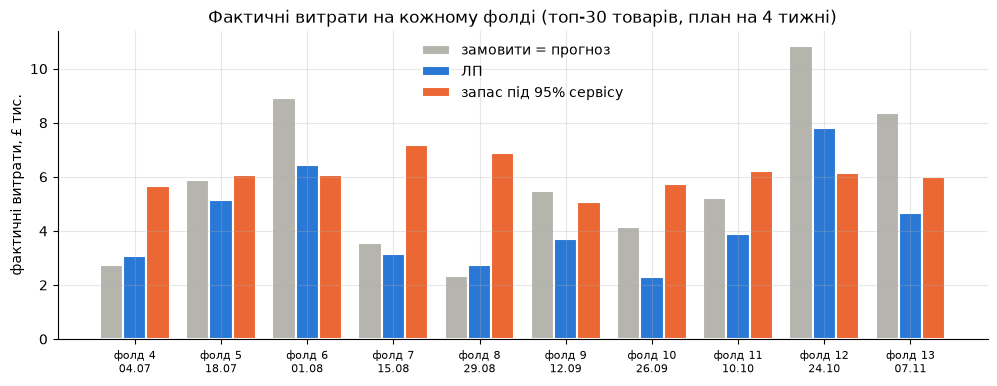

In [17]:
plots.policy_costs_by_fold(policy_costs)

- **На 10 фолдах ЛП знижує фактичні витрати на ~25%** проти «замовити = прогноз» (медіана по фолдах — близько −27%) і виграє у 8 фолдах з 10. Результат тримається, але він удвічі скромніший за −44% з одного фолду.
- Обидва фолди, де ЛП програє (4 і 8), — це періоди, коли попит виявився **нижчим** за прогноз: страховий запас тоді просто лежить.
- **Евристика «95% сервісу» гірша за звичайний прогноз** (+6%): вона тримає забагато запасу. Тобто виграє не «більше запасу», а запас, підібраний під співвідношення витрат.
- Обмеження місткості коштує ~4 п.п. виграшу.

### 4.4 Чутливість до вартості залишку $h$

Повторюємо перевірку на всіх фолдах для різних $h$: від «залишок переходить далі» до «непроданий товар пропадає повністю». Кожну політику оцінюємо в тих самих витратах, під які її оптимізували.

,"h, % ціни продажу","ЛП vs прогноз, %",ЛП: фолдів краще за прогноз,"95% сервісу vs прогноз, %"
p/(p+h),,,,
0.82,9.00,-25.39,8/10,6.05
0.67,20.00,-6.32,6/10,86.89
0.50,40.00,5.36,4/10,192.61
0.40,60.00,3.17,4/10,265.91


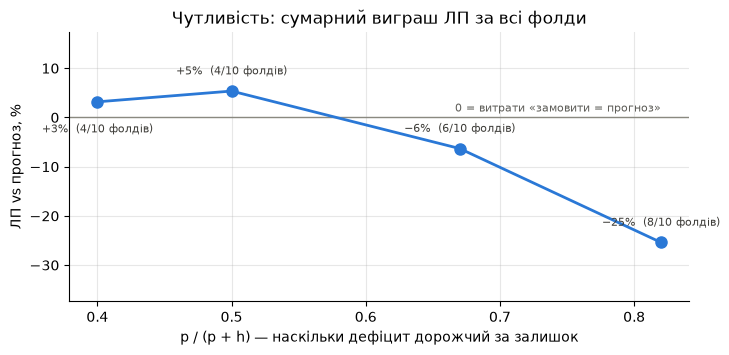

In [18]:
sensitivity = {}
for share in cfg.HOLDING_SHARE_GRID:
    costs_by_fold = (policy_costs if share == cfg.HOLDING_SHARE else
                     opt.backtest_policies(sku_predictions[best], sku_panel, origins, gold["prices"],
                                           gold_weekly.index, holding_share=share, with_capacity=False))
    summary = opt.savings_summary(costs_by_fold)
    vs_col = summary.columns[1]
    sensitivity[round(opt.critical_ratio(share), 2)] = {
        "h, % ціни продажу": share * cfg.COST_SHARE * 100,
        "ЛП vs прогноз, %": summary.loc[opt.LP, vs_col],
        "ЛП: фолдів краще за прогноз": f"{summary.loc[opt.LP, summary.columns[3]]}/{len(costs_by_fold)}",
        "95% сервісу vs прогноз, %": summary.loc[opt.SERVICE, vs_col],
    }

sensitivity = pd.DataFrame(sensitivity).T.rename_axis("p/(p+h)")
display(sensitivity)
plots.lp_sensitivity(sensitivity.astype({"ЛП vs прогноз, %": float}),
                     "ЛП vs прогноз, %", "ЛП: фолдів краще за прогноз")

**Виграш від оптимізації повністю залежить від припущення про $h$:**
- поки залишок дешевий ($p/(p+h) ≈ 0.8$) — ЛП стабільно краще (−25%);
- при $p/(p+h) ≈ 0.67$ виграш падає до ~6%;
- коли залишок коштує стільки ж або більше, ніж втрачена маржа ($p/(p+h) ≤ 0.5$), **ЛП стає гіршим за звичайний прогноз**.

Чому так: у таких умовах ЛП замовляє близько медіани сценаріїв або нижче, а сценарії будуються з помилок літніх фолдів і **не знають про осіннє зростання**: восени прогноз систематично занижений (колонка «факт vs прогноз» у 4.3: до +44%). Тобто проблема не в оптимізації, а в **калібруванні розподілу попиту**. Оптимізація підсилює і якість, і помилки сценаріїв.

Висновок для наступних етапів: (1) з'ясувати реальні витрати на залишок (чи переходить товар у наступний сезон); (2) будувати сценарії з урахуванням сезону — квантильні прогнози або помилки, прив'язані до періоду року.

### 4.5 Поточні обмеження
- **Немає даних про залишки на складі, lead time, об'єм/вагу товарів і собівартість** — витрати й місткість задані припущеннями, а результат, як показано в 4.4, від них сильно залежить.
- **Сценарії не враховують сезонність помилки** — помилки з літа переносяться на осінній пік.
- **Продажі ≠ попит**: коли товару не було на складі, продажів 0, хоча попит був (цензуровані дані).
- **Помилки сценаріїв незалежні між товарами**, хоча сезонний пік б'є по всіх товарах одночасно.
- Прогноз по товарах поки слабкий (WAPE ~60%), моделі недооцінюють осінній пік.
- Одноперіодна модель: перенесення залишку враховано лише через мале $h$, а не явно.
- Фолди перетинаються (крок 2 тижні, горизонт 4), тож кожен тиждень входить у дві оцінки — сума по фолдах є середньою оцінкою, а не сумою реальних витрат за період.

---
## 5. Висновки та наступні кроки

**Висновки:**
1. **Дані** організовано в шари bronze → silver → gold (`src/pipeline.py`) з 19 перевірками якості. Silver: нормалізовано коди товарів, прибрано дублі перекриття аркушів, скасування, службові коди й фальшиві мега-замовлення (залишилось ~94% рядків). Gold: тижневий ряд з прапорцями аномалій і ознаками, матриця тиждень × товар, довідник товарів з ABC-класами, ціни по тижнях.
2. **Валідація** — rolling-origin backtest, 13 фолдів, горизонт 4 тижні; відсутність leakage в ознаках перевірена кодом.
3. **Прогноз:** загальний ряд — ETS і Ridge + Fourier (WAPE 15–16%, MASE ≈ 0.7); товари — MA(8), WAPE ~60%.
4. **Оптимізація:** стохастичне ЛП перевірене тим самим rolling-origin на 10 фолдах: −25% фактичних витрат проти «замовити = прогноз», краще у 8 з 10 фолдів, і краще за евристику «95% сервісу». Але виграш тримається лише тоді, коли залишок дешевий ($p/(p+h) ≈ 0.8$); при дорогому залишку ЛП програє прогнозу, бо сценарії не враховують осіннє зростання.

**Наступні кроки (за планом курсу):**
- *Складніші моделі*: глобальна LightGBM по всіх товарах (лаги, ціна, календар), Croston/TSB для переривчастих товарів, квантильні прогнози. Ознаки — нові колонки в gold, моделі — нові функції в `src/models.py`, той самий `backtest`.
- *Explainability*: SHAP для градієнтного бустингу — які ознаки рухають прогноз; пояснення рекомендацій замовлення.
- *Сценарії попиту*: калібрувати під сезон (квантильні прогнози або помилки, прив'язані до періоду року) — це зараз головне вузьке місце оптимізації.
- *Оптимізація*: багатоперіодна модель з перенесенням залишків, lead time, бюджетом, об'ємом товарів (MILP з мінімальною партією).
- *Симуляція*: Monte-Carlo сценарії для складу (сплеск попиту, затримка постачання, зменшення місткості) з корельованими помилками між товарами.